# TP — Régression linéaire simple et multiple
**Dataset : Diabetes (Scikit-learn)** — cible : progression de la maladie un an après les mesures initiales.

## Introduction

L'objectif de ce TP est d'utiliser la régression linéaire simple et multiple pour prédire la progression de la maladie du diabète à partir du dataset Diabetes de Scikit-learn.


## 1. Prétraitement des données

In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (mean_squared_error, mean_absolute_error, r2_score,
                             accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, ConfusionMatrixDisplay)

### 1.1 Chargement et exploration

Les 10 variables explicatives sont : `age`, `sex`, `bmi` (indice de masse corporelle), `bp` (pression artérielle moyenne), `s1` à `s6` (mesures sanguines). Elles sont déjà centrées et mises à l'échelle par Scikit-learn.

In [18]:
data = load_diabetes(as_frame=True)
df = data.frame
print("Dimensions :", df.shape)
print("Variables explicatives :", list(data.feature_names))
print("Variable cible : target")
df.head()

Dimensions : (442, 11)
Variables explicatives : ['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']
Variable cible : target


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


### 1.2 Statistiques descriptives

In [19]:
stats = df.describe().T
stats['median'] = df.median()
stats[['mean','median','std','min','max']]

,mean,median,std,min,max
age,-2.511817e-19,0.005383,0.047619,-0.107226,0.110727
sex,1.230790e-17,-0.044642,0.047619,-0.044642,0.050680
bmi,-2.245564e-16,-0.007284,0.047619,-0.090275,0.170555
bp,-4.797570e-17,-0.005670,0.047619,-0.112399,0.132044
s1,-1.381499e-17,-0.004321,0.047619,-0.126781,0.153914
s2,3.918434e-17,-0.003819,0.047619,-0.115613,0.198788
s3,-5.777179e-18,-0.006584,0.047619,-0.102307,0.181179
s4,-9.042540e-18,-0.002592,0.047619,-0.076395,0.185234
s5,9.268604e-17,-0.001947,0.047619,-0.126097,0.133597
s6,1.130318e-17,-0.001078,0.047619,-0.137767,0.135612



### Interprétation

Les statistiques descriptives permettent de comprendre la distribution des variables.

La variable cible possède une moyenne de 152,13 et un écart-type de 77,09. Cela indique une dispersion importante des valeurs de progression de la maladie entre les patients.

Les variables explicatives sont centrées autour de zéro, ce qui confirme leur prétraitement.


### 1.3 Valeurs manquantes et doublons

In [20]:
print("Valeurs manquantes par colonne :\n", df.isnull().sum())
print("Nombre de doublons :", df.duplicated().sum())

Valeurs manquantes par colonne :
 age       0
sex       0
bmi       0
bp        0
s1        0
s2        0
s3        0
s4        0
s5        0
s6        0
target    0
dtype: int64
Nombre de doublons : 0



### Interprétation

Le résultat montre qu'il n'existe aucune valeur manquante dans les colonnes du dataset et aucun doublon.

Les données sont donc propres et ne nécessitent pas de traitement supplémentaire pour ces deux problèmes.


### 1.4 Corrélations

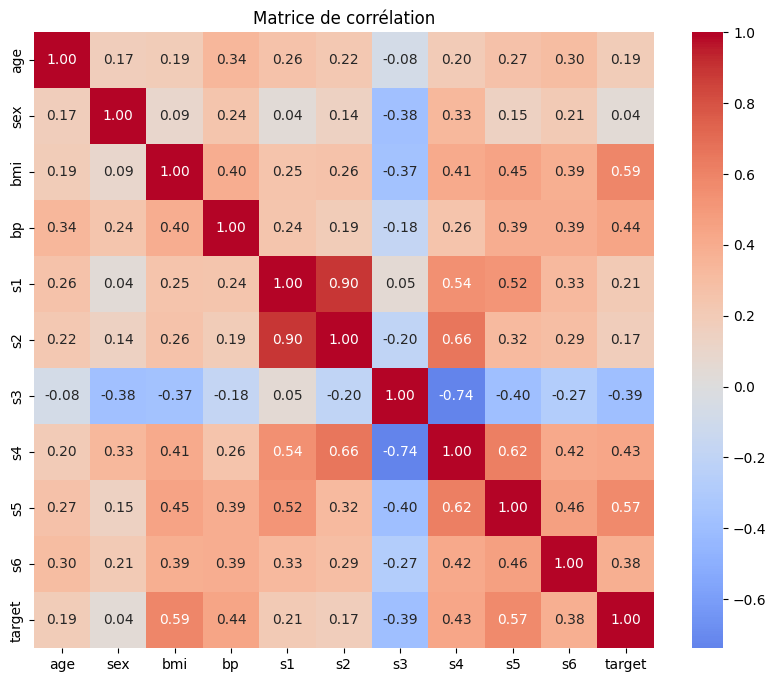

bmi    0.586450
s5     0.565883
bp     0.441482
s4     0.430453
s6     0.382483
s1     0.212022
age    0.187889
s2     0.174054
sex    0.043062
s3    -0.394789
Name: target, dtype: float64


In [21]:
corr = df.corr()
plt.figure(figsize=(10,8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Matrice de corrélation")
plt.show()
print(corr['target'].drop('target').sort_values(ascending=False))


### Interprétation

La matrice de corrélation permet d'étudier les relations entre les variables.

La variable `bmi` présente la corrélation positive la plus élevée avec la cible (0,586), suivie de `s5` (0,566) et `bp` (0,441).

La variable `s3` présente une corrélation négative (-0,395).

Ces résultats montrent que certaines variables sont davantage liées à la progression de la maladie et peuvent être utiles pour la prédiction.


### 1.5 Relations variables explicatives / cible

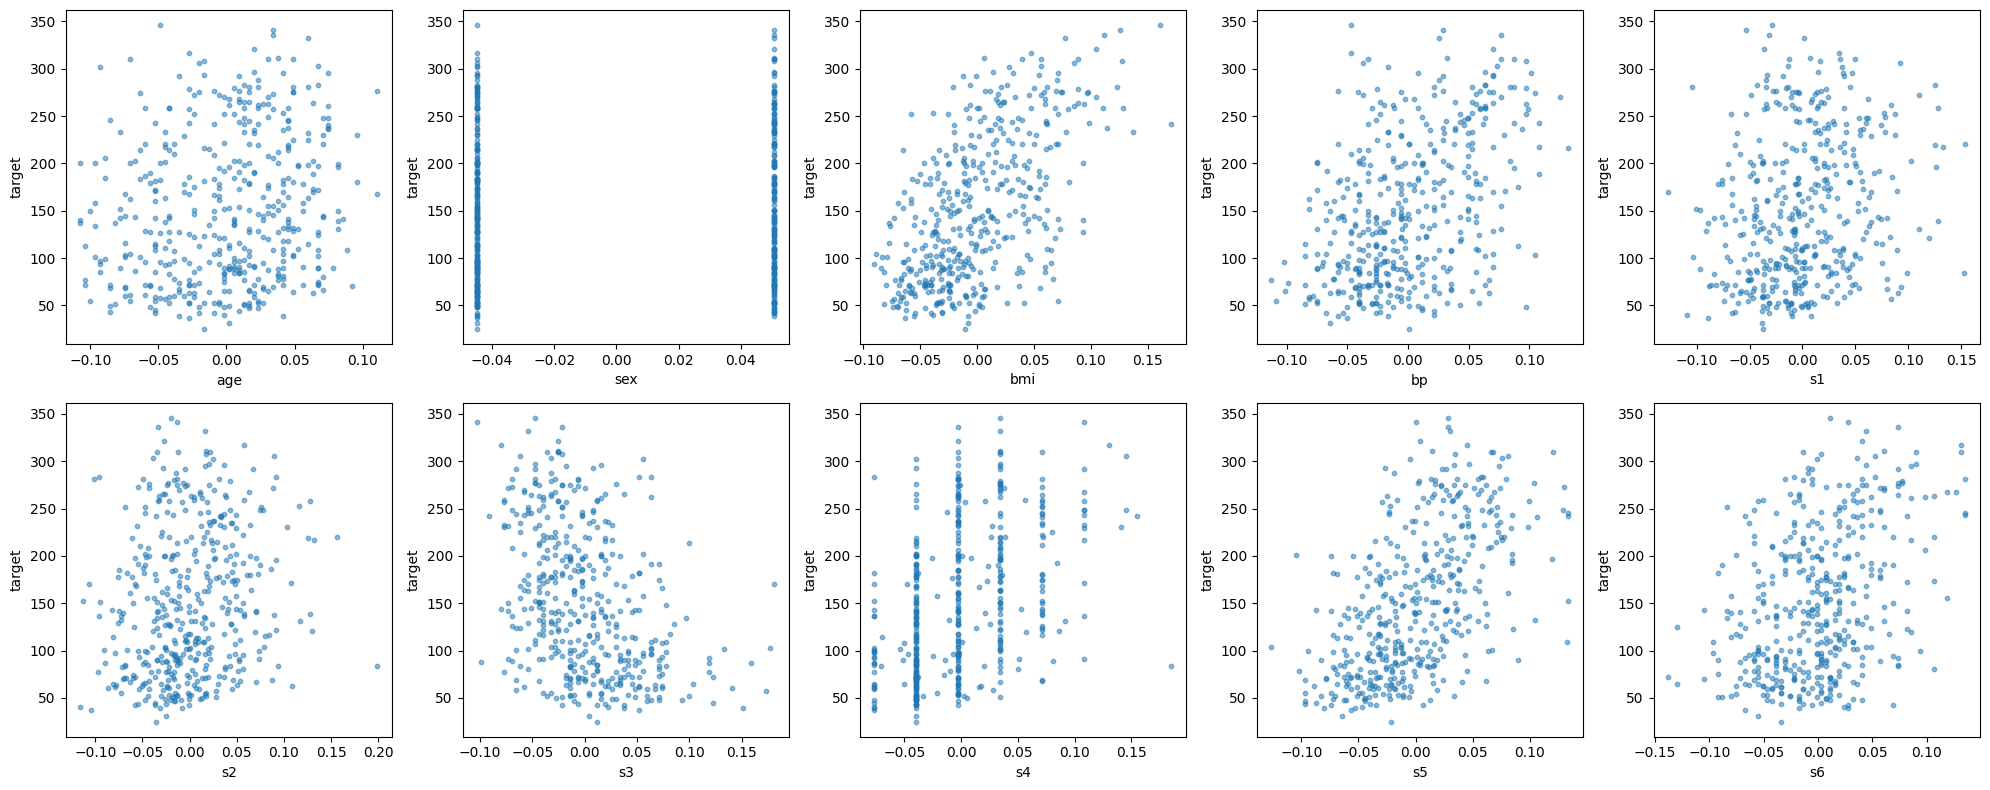

In [22]:
fig, axes = plt.subplots(2, 5, figsize=(20, 8))
for ax, col in zip(axes.ravel(), data.feature_names):
    ax.scatter(df[col], df['target'], alpha=0.5, s=10)
    ax.set_xlabel(col); ax.set_ylabel('target')
plt.tight_layout(); plt.show()


### Interprétation

Les graphiques permettent d'observer la relation entre chaque variable explicative et la progression de la maladie.

On remarque notamment une tendance croissante entre `bmi` et `target`. Cependant, les points sont dispersés autour de cette tendance.

Cela montre que la relation entre les variables et la cible n'est pas parfaitement linéaire et que plusieurs facteurs peuvent influencer la progression de la maladie.


### 1.6 Séparation apprentissage / test

In [23]:
X = df[data.feature_names]
y = df['target']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(X_train.shape, X_test.shape)

(353, 10) (89, 10)


## 2. Régression linéaire simple
Principe : modéliser la cible par une droite **Y = aX + b** où Y = `target`, X = `bmi`, a = pente (slope), b = ordonnée à l'origine (intercept). Les coefficients minimisent la somme des carrés des erreurs (moindres carrés).

In [24]:
Xtr_s, Xte_s = X_train[['bmi']], X_test[['bmi']]
slr = LinearRegression().fit(Xtr_s, y_train)
a, b = slr.coef_[0], slr.intercept_
print(f"a (slope)     = {a:.4f}")
print(f"b (intercept) = {b:.4f}")
print(f"Equation : target = {a:.2f} * bmi + {b:.2f}")

a (slope)     = 998.5777
b (intercept) = 152.0034
Equation : target = 998.58 * bmi + 152.00



## Interprétation

Le modèle utilise uniquement la variable `bmi` pour prédire la progression de la maladie.

L'équation obtenue est :

$$
target = 998,58 \times bmi + 152,00
$$

La pente est positive, ce qui signifie qu'une augmentation du BMI est associée à une augmentation de la progression prédite.

Le graphique montre que les observations sont dispersées autour de la droite de régression. De plus, les valeurs réelles et prédites dans le tableau présentent parfois des différences importantes.

On peut donc conclure que le BMI permet d'expliquer une partie de la progression de la maladie, mais qu'il ne suffit pas à réaliser des prédictions très précises.


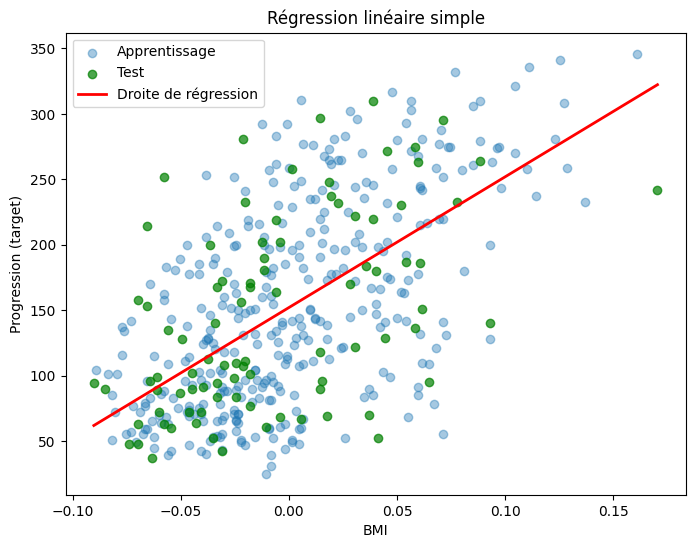

In [25]:
y_pred_s = slr.predict(Xte_s)
plt.figure(figsize=(8,6))
plt.scatter(Xtr_s, y_train, alpha=0.4, label='Apprentissage')
plt.scatter(Xte_s, y_test, alpha=0.7, color='green', label='Test')
xs = np.linspace(X['bmi'].min(), X['bmi'].max(), 100).reshape(-1,1)
plt.plot(xs, slr.predict(pd.DataFrame(xs, columns=['bmi'])), color='red', lw=2, label='Droite de régression')
plt.xlabel('BMI'); plt.ylabel('Progression (target)'); plt.legend()
plt.title('Régression linéaire simple'); plt.show()

In [26]:
pd.DataFrame({'Réel': y_test.values[:10], 'Prédit': y_pred_s[:10].round(1)})

,Réel,Prédit
0,219.0,145.8
1,70.0,188.9
2,202.0,148.0
3,230.0,203.9
4,111.0,131.8
5,84.0,127.5
6,242.0,322.3
7,272.0,197.5
8,94.0,61.9
9,96.0,167.3


**Analyse :** a > 0 signifie qu'une augmentation du BMI est associée à une progression plus forte de la maladie. La dispersion autour de la droite montre qu'une seule variable n'explique qu'une partie de la variance (voir R² plus bas).

## 3. Régression linéaire multiple
Principe : **Y = b0 + b1·X1 + b2·X2 + … + bn·Xn** avec toutes les variables explicatives.

b0 (intercept) = 151.3456
s1    -931.489
sex   -241.964
age     37.904
s6      48.671
s3     163.420
s4     275.318
bp     347.704
s2     518.062
bmi    542.429
s5     736.199
dtype: float64


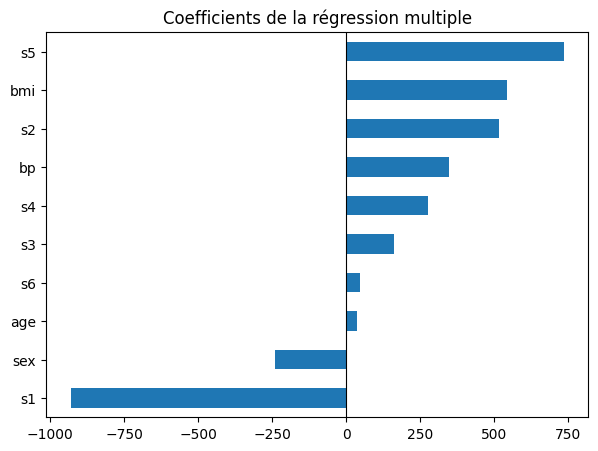

In [27]:
mlr = LinearRegression().fit(X_train, y_train)
print(f"b0 (intercept) = {mlr.intercept_:.4f}")
coefs = pd.Series(mlr.coef_, index=X.columns).sort_values()
print(coefs.round(3))
coefs.plot(kind='barh', figsize=(7,5), title='Coefficients de la régression multiple')
plt.axvline(0, color='k', lw=0.8); plt.show()

In [28]:
eq = " + ".join([f"({c:.1f}·{n})" for n, c in zip(X.columns, mlr.coef_)])
print(f"target = {mlr.intercept_:.1f} + {eq}")
y_pred_m = mlr.predict(X_test)

target = 151.3 + (37.9·age) + (-242.0·sex) + (542.4·bmi) + (347.7·bp) + (-931.5·s1) + (518.1·s2) + (163.4·s3) + (275.3·s4) + (736.2·s5) + (48.7·s6)


**Interprétation :** les variables ayant les plus grands coefficients en valeur absolue (variables déjà standardisées, donc comparables) sont les plus influentes ; un signe positif augmente la progression prédite, un signe négatif la diminue, toutes choses égales par ailleurs. Les variables `s1` à `s6` sont fortement corrélées entre elles (multicolinéarité), ce qui peut rendre certains coefficients instables.

## 4. Évaluation des performances
### 4.1 Métriques de régression (adaptées au problème)
La cible est **continue** : Accuracy, Precision, Recall, F1 et matrice de confusion sont des métriques de **classification** et ne s'appliquent pas directement. On utilise MSE, RMSE, MAE et R².

In [29]:
def reg_metrics(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    return {'MSE': mse, 'RMSE': np.sqrt(mse),
            'MAE': mean_absolute_error(y_true, y_pred),
            'R²': r2_score(y_true, y_pred)}

res = pd.DataFrame({'Simple (BMI)': reg_metrics(y_test, y_pred_s),
                    'Multiple (10 variables)': reg_metrics(y_test, y_pred_m)}).T
res

,MSE,RMSE,MAE,R²
Simple (BMI),4061.825928,63.732456,52.259976,0.233350
Multiple (10 variables),2900.193628,53.853446,42.794095,0.452603



### Interprétation

Les résultats montrent que la régression multiple obtient de meilleures performances que la régression simple.

Le RMSE passe de 63,73 à 53,85 et le MAE passe de 52,26 à 42,79. Cela signifie que les erreurs de prédiction sont plus faibles avec le modèle multiple.

Le coefficient de détermination R² passe de 0,233 à 0,453. Le modèle multiple explique donc une plus grande partie de la variation de la cible.

Le graphique des valeurs réelles et prédites confirme que le modèle multiple fournit des prédictions globalement plus proches des valeurs réelles.


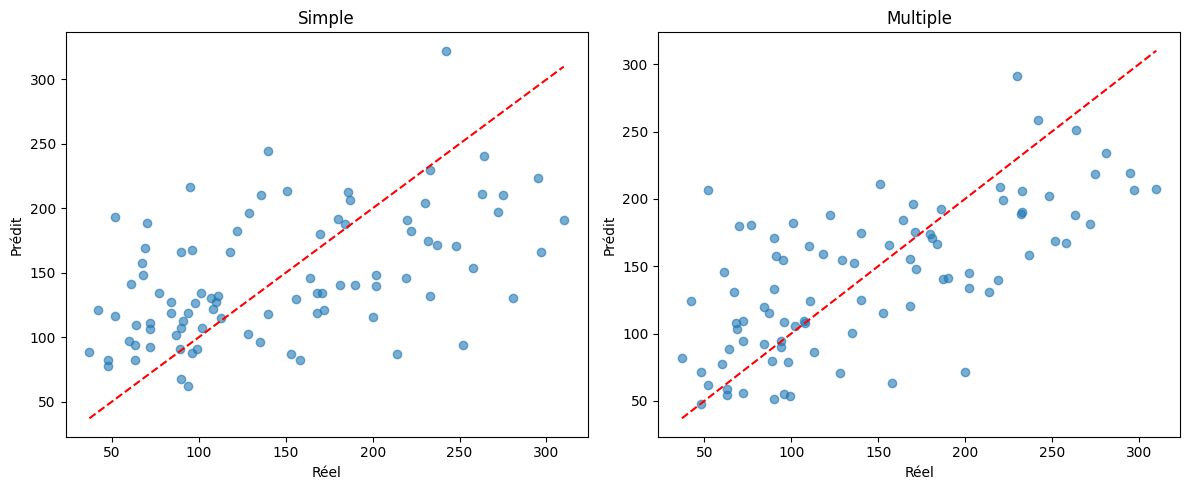

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(12,5))
for ax, yp, t in zip(axes, [y_pred_s, y_pred_m], ['Simple', 'Multiple']):
    ax.scatter(y_test, yp, alpha=0.6)
    lim = [y_test.min(), y_test.max()]
    ax.plot(lim, lim, 'r--'); ax.set_xlabel('Réel'); ax.set_ylabel('Prédit'); ax.set_title(t)
plt.tight_layout(); plt.show()

### 4.2 Métriques de classification 
Pour les calculer, on **binarise** la cible : classe 1 (progression élevée) si `target` > médiane du jeu d'apprentissage, sinon 0. Les prédictions de régression sont binarisées avec le même seuil.

,Accuracy,Precision,Recall,F1-score
Simple (BMI),0.685393,0.657895,0.625,0.641026
Multiple,0.741573,0.688889,0.775,0.729412


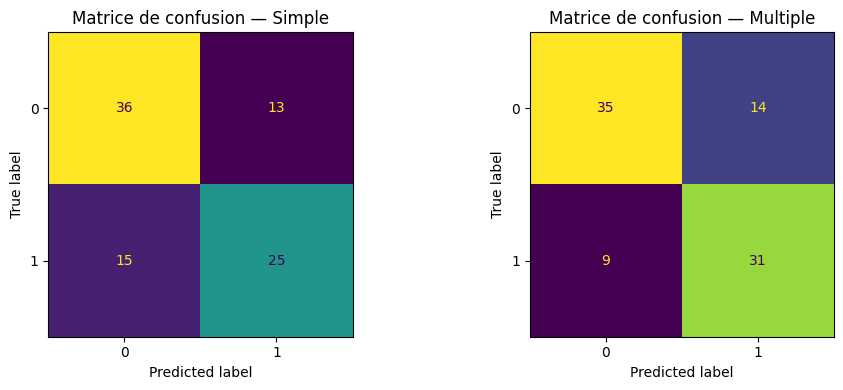

In [31]:
seuil = y_train.median()
yb_true = (y_test > seuil).astype(int)

def clf_metrics(yp):
    yb_pred = (yp > seuil).astype(int)
    return {'Accuracy': accuracy_score(yb_true, yb_pred),
            'Precision': precision_score(yb_true, yb_pred),
            'Recall': recall_score(yb_true, yb_pred),
            'F1-score': f1_score(yb_true, yb_pred)}, yb_pred

m_s, yb_s = clf_metrics(y_pred_s)
m_m, yb_m = clf_metrics(y_pred_m)
display(pd.DataFrame({'Simple (BMI)': m_s, 'Multiple': m_m}).T)

fig, axes = plt.subplots(1, 2, figsize=(10,4))
for ax, yb, t in zip(axes, [yb_s, yb_m], ['Simple', 'Multiple']):
    ConfusionMatrixDisplay(confusion_matrix(yb_true, yb)).plot(ax=ax, colorbar=False)
    ax.set_title(f'Matrice de confusion — {t}')
plt.tight_layout(); plt.show()

La cible a été transformée en deux classes à l'aide de la médiane du jeu d'apprentissage.

| Modèle | Accuracy | F1-score |
|---|---:|---:|
| Simple | 68,54 % | 0,641 |
| Multiple | 74,16 % | 0,729 |

**Interprétation :** La régression multiple obtient de meilleurs résultats pour la classification des patients selon leur niveau de progression.


## 5. Conclusion
- La régression multiple obtient un R² plus élevé et des erreurs (RMSE, MAE) plus faibles que la simple : plusieurs variables expliquent mieux la progression de la maladie que le BMI seul.
- Le BMI reste l'une des variables les plus corrélées à la cible, avec `s5` et `bp`.
- Le R² reste modéré : la relation n'est pas purement linéaire et le dataset est bruité ; des modèles non linéaires ou régularisés (Ridge, Lasso) pourraient améliorer les résultats.
- Les métriques de classification n'ont de sens qu'après discrétisation de la cible.